# Análise exploratória — Brasil × CBIS-DDSM

**Pergunta principal:** em que medida as características dos casos do CBIS-DDSM são compatíveis com o perfil
epidemiológico do câncer de mama no Brasil?

Este notebook usa os dados coletados pelos scrapers e os metadados do CBIS-DDSM. Está dividido em três partes:

1. **Brasil**: mamografias no SUS, incidência e mortalidade (2018–2022);
2. **CBIS-DDSM**: perfil das lesões e associação das características clínicas com malignidade;
3. **Comparação**: o que é e o que não é comparável entre as duas bases.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from src import config
from src.analysis.estatistica import teste_associacao
from src.processing.cbis import carrega_cbis
from src.visualization import estilo
from src.visualization.estilo import AZUL, LARANJA, VERDE_AGUA, salvar

estilo.aplicar()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

I = config.INTERIM
inca_mamo = pd.read_csv(I / "inca_mamografias_sus.csv")
inca_inc = pd.read_csv(I / "inca_incidencia.csv")
inca_mort = pd.read_csv(I / "inca_mortalidade.csv")
sia_diag = pd.read_csv(I / "datasus_sia_mamografia_diagnostica_uf_ano.csv")
sia_rast = pd.read_csv(I / "datasus_sia_mamografia_rastreamento_uf_ano.csv")
sim_uf = pd.read_csv(I / "datasus_sim_obitos_mama_uf_ano.csv")
sim_faixa = pd.read_csv(I / "datasus_sim_obitos_mama_faixa_ano.csv")
cbis = carrega_cbis()

## 1. Brasil

### 1.1 Mamografias no SUS, 2018–2022

Fonte: SIA/SUS via TABNET (quantidade apresentada, todas as idades). Rastreamento = procedimento 0204030188;
diagnóstica = 0204030030.

In [2]:
serie = pd.DataFrame({
    "Rastreamento": sia_rast.query("nivel == 'brasil'").set_index("ano")["valor"],
    "Diagnóstica": sia_diag.query("nivel == 'brasil'").set_index("ano")["valor"],
})
serie["Total"] = serie.sum(axis=1)
serie["% rastreamento"] = 100 * serie["Rastreamento"] / serie["Total"]
serie["variação vs 2019 (%)"] = 100 * (serie["Total"] / serie.loc[2019, "Total"] - 1)
serie

,Rastreamento,Diagnóstica,Total,% rastreamento,variação vs 2019 (%)
ano,,,,,
2018,"3,911,399.00","384,523.00","4,295,922.00",91.05,0.43
2019,"3,893,311.00","384,400.00","4,277,711.00",91.01,0.00
2020,"2,271,789.00","300,447.00","2,572,236.00",88.32,-39.87
2021,"3,148,032.00","358,840.00","3,506,872.00",89.77,-18.02
2022,"3,865,428.00","386,006.00","4,251,434.00",90.92,-0.61


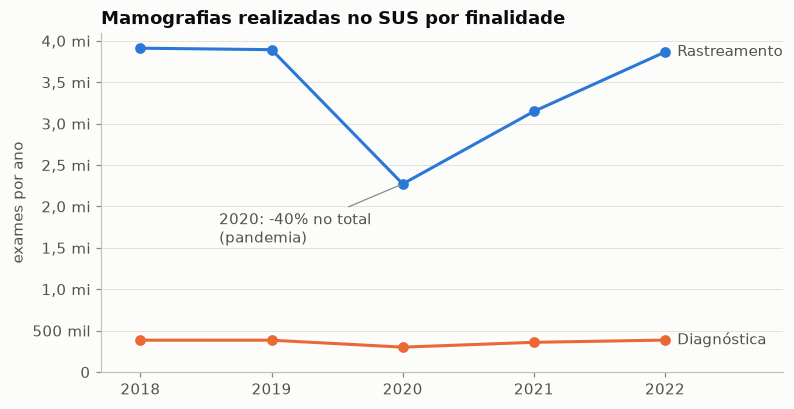

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for col, cor in [("Rastreamento", AZUL), ("Diagnóstica", LARANJA)]:
    ax.plot(serie.index, serie[col], marker="o", markersize=6, color=cor)
    ax.annotate(col, (serie.index[-1], serie[col].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=estilo.TINTA_SECUNDARIA)
queda = serie.loc[2020, "variação vs 2019 (%)"]
ax.annotate(f"2020: {queda:.0f}% no total\n(pandemia)", (2020, serie.loc[2020, "Rastreamento"]),
            xytext=(2018.6, serie["Rastreamento"].max() * 0.4), color=estilo.TINTA_SECUNDARIA,
            arrowprops=dict(arrowstyle="-", color=estilo.TINTA_SUAVE, lw=0.8))
ax.set_xticks(serie.index)
ax.set_xlim(2017.7, 2022.9)
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(estilo.milhar))
ax.set_title("Mamografias realizadas no SUS por finalidade")
ax.set_ylabel("exames por ano")
salvar(fig, "01_mamografias_sus_serie")

### 1.2 Para quem as mamografias são feitas: faixa etária (2022)

Fonte: INCA
Os totais são calculados **somando as regiões**, porque a
linha "Total" da Tabela Diagnóstico tem um erro de digitação na fonte (ver `docs/scraping_inca.md`).

In [4]:
def por_faixa(tabela):
    t = inca_mamo.query("tabela == @tabela and nivel == 'regiao'")
    s = t.groupby("faixa_etaria", sort=False)["valor"].sum()
    return (100 * s / s.sum()).rename("%")

rast_faixa = por_faixa(3)
diag_faixa = por_faixa(5)
print("Rastreamento:"); display(rast_faixa.round(1).to_frame())
print("Diagnóstica:"); display(diag_faixa.round(1).to_frame())

Rastreamento:


,%
faixa_etaria,
35 a 39 anos,1.70
40 a 49 anos,26.60
50 a 69 anos,65.90
> 70 anos,5.80


Diagnóstica:


,%
faixa_etaria,
<30,1.50
30 a 39,6.00
40 a 49,24.30
50 a 59,29.30
60 a 69,24.80
>70,14.00


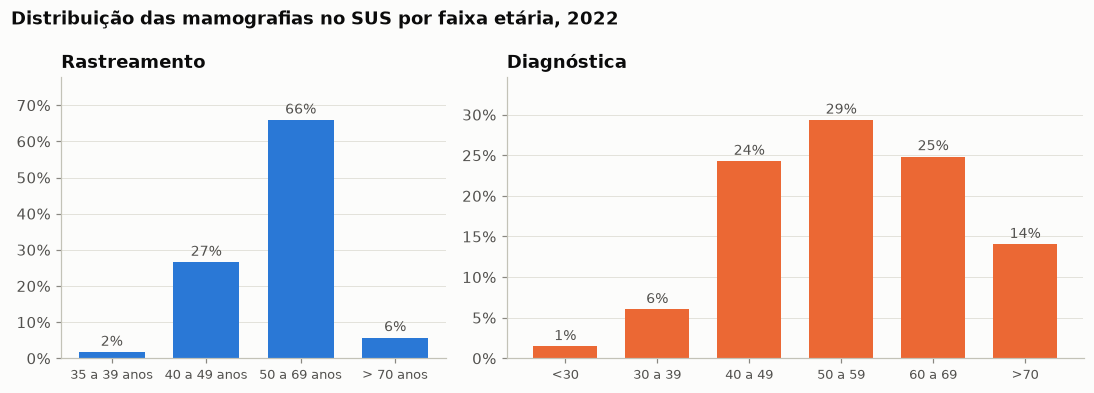

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [4, 6]})
for ax, s, titulo, cor in [(axes[0], rast_faixa, "Rastreamento", AZUL), (axes[1], diag_faixa, "Diagnóstica", LARANJA)]:
    barras = ax.bar(s.index, s.values, color=cor, width=0.7)
    ax.bar_label(barras, fmt="%.0f%%", padding=2, color=estilo.TINTA_SECUNDARIA, fontsize=9)
    ax.set_title(titulo)
    ax.set_ylim(0, s.max() * 1.18)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.tick_params(axis="x", labelsize=8.5)
fig.suptitle("Distribuição das mamografias no SUS por faixa etária, 2022", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "02_mamografias_faixa_etaria")

### 1.3 Mortalidade por câncer de mama (SIM), 2018–2022

Óbitos de mulheres com causa básica "neoplasia maligna da mama" (CID-BR-10 041), por residência.

In [6]:
obitos_ano = sim_uf.query("nivel == 'brasil'").set_index("ano")["valor"]
print("Óbitos por ano:", obitos_ano.astype(int).to_dict())

faixa = (sim_faixa.query("faixa_etaria != 'Idade ignorada'")
         .groupby("faixa_etaria", sort=False)["valor"].sum())
faixa_pct = 100 * faixa / faixa.sum()

grupos = {
    "< 50 anos": ["15 a 19 anos", "20 a 29 anos", "30 a 39 anos", "40 a 49 anos"],
    "50 a 69 anos": ["50 a 59 anos", "60 a 69 anos"],
    "70 anos ou mais": ["70 a 79 anos", "80 anos e mais"],
}
obitos_grupo = pd.Series({g: faixa_pct[f].sum() for g, f in grupos.items()}).rename("% dos óbitos 2018–2022")
obitos_grupo.round(1).to_frame()

Óbitos por ano: {2018: 17572, 2019: 18068, 2020: 17825, 2021: 18139, 2022: 19103}


,% dos óbitos 2018–2022
< 50 anos,21.90
50 a 69 anos,45.00
70 anos ou mais,33.10


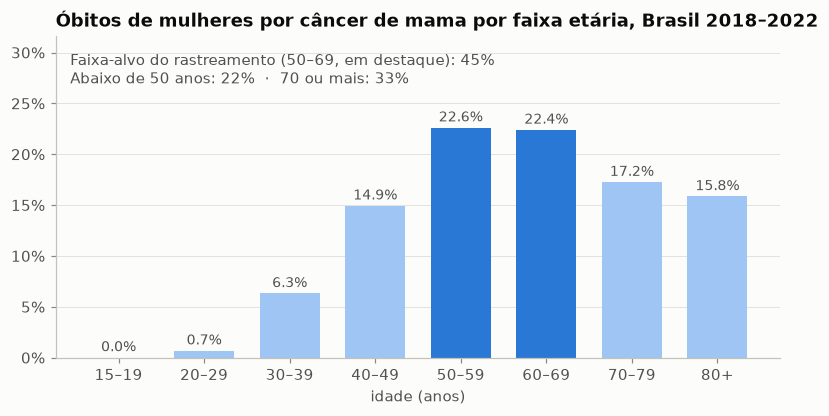

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
cores = [AZUL if f in grupos["50 a 69 anos"] else estilo.SEQUENCIAL_AZUL[1] for f in faixa_pct.index]
rotulos = [f.replace(" anos e mais", "+").replace(" anos", "").replace(" a ", "–") for f in faixa_pct.index]
barras = ax.bar(rotulos, faixa_pct.values, color=cores, width=0.7)
ax.bar_label(barras, fmt="%.1f%%", padding=2, color=estilo.TINTA_SECUNDARIA, fontsize=9)
ax.set_ylim(0, faixa_pct.max() * 1.4)  # espaço para o texto-resumo acima das barras
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("idade (anos)")
ax.set_title("Óbitos de mulheres por câncer de mama por faixa etária, Brasil 2018–2022")
ax.text(0.02, 0.95, f"Faixa-alvo do rastreamento (50–69, em destaque): {obitos_grupo['50 a 69 anos']:.0f}%\n"
        f"Abaixo de 50 anos: {obitos_grupo['< 50 anos']:.0f}%  ·  70 ou mais: {obitos_grupo['70 anos ou mais']:.0f}%",
        transform=ax.transAxes, ha="left", va="top", color=estilo.TINTA_SECUNDARIA)
salvar(fig, "03_obitos_faixa_etaria")

### 1.4 Diferenças regionais

Para cada região: casos novos estimados (INCA, 2023; soma das UFs, que corrige o erro do Sudeste na fonte),
taxa de mortalidade ajustada (INCA, 2021), óbitos (SIM, 2022) e mamografias de rastreamento (SIA, 2022).
**Rastreamentos por caso estimado** é um indicador simples da intensidade do rastreamento em relação à carga da
doença na região.

In [8]:
casos = inca_inc.query("indicador == 'casos_estimados' and nivel == 'uf'").groupby("regiao")["valor"].sum()
taxa_inc = inca_inc.query("indicador == 'taxa_ajustada_100mil' and nivel == 'regiao'").set_index("localidade")["valor"]
regioes = pd.DataFrame({
    "casos_estimados_2023": casos,
    "taxa_incidencia_ajustada": taxa_inc,
    "taxa_mortalidade_ajustada_2021": inca_mort.query("nivel == 'regiao'").set_index("localidade")["valor"],
    "obitos_2022": sim_uf.query("nivel == 'regiao' and ano == 2022").set_index("localidade")["valor"],
    "rastreamentos_2022": sia_rast.query("nivel == 'regiao' and ano == 2022").set_index("localidade")["valor"],
})
regioes["rastreamentos_por_caso"] = regioes["rastreamentos_2022"] / regioes["casos_estimados_2023"]
regioes = regioes.sort_values("rastreamentos_por_caso")
regioes

,casos_estimados_2023,taxa_incidencia_ajustada,taxa_mortalidade_ajustada_2021,obitos_2022,rastreamentos_2022,rastreamentos_por_caso
Centro-Oeste,"4,950.00",47.31,10.90,"1,289.00","198,524.00",40.11
Sudeste,"39,330.00",52.83,12.43,"9,374.00","1,894,192.00",48.16
Norte,"2,410.00",27.73,8.59,905.00,"129,539.00",53.75
Nordeste,"15,690.00",42.11,10.75,"4,195.00","898,798.00",57.28
Sul,"11,230.00",41.06,12.69,"3,340.00","744,375.00",66.28


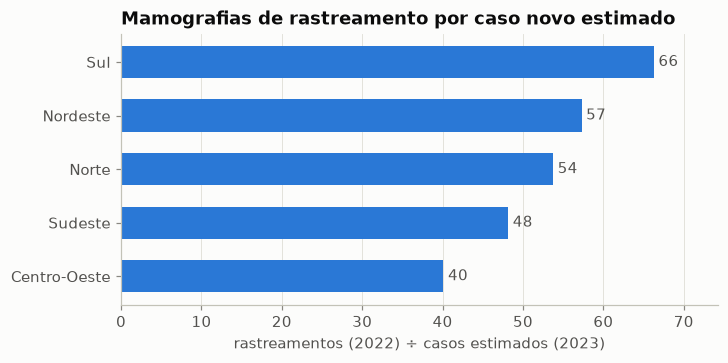

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
barras = ax.barh(regioes.index, regioes["rastreamentos_por_caso"], color=AZUL, height=0.6)
ax.bar_label(barras, fmt="%.0f", padding=3, color=estilo.TINTA_SECUNDARIA)
ax.set_xlim(0, regioes["rastreamentos_por_caso"].max() * 1.12)
ax.set_title("Mamografias de rastreamento por caso novo estimado")
ax.set_xlabel("rastreamentos (2022) ÷ casos estimados (2023)")
salvar(fig, "04_rastreamento_por_caso_regiao")

### 1.4.1 Cobertura, incidência e mortalidade por região

O indicador acima compara exames com casos. Para comparar as regiões também com o **tamanho da população**,
estimamos o número de mulheres de cada UF pelo próprio INCA: população ≈ casos estimados ÷ taxa bruta × 100 mil.
Com isso, calculamos:

- **rastreamentos por 1.000 mulheres** (SIA 2022): cobertura relativa do rastreamento no SUS;
- **óbitos por caso estimado** (SIM 2022 ÷ INCA 2023): não é letalidade (são grupos de mulheres diferentes), mas
  serve para comparar as regiões entre si; valores altos sugerem diagnóstico mais tardio;
- **variação do rastreamento** em 2020 e em 2022, em relação a 2019 (efeito da pandemia).

**Cuidados:** a população é de mulheres de **todas as idades**, não só da faixa-alvo (50–69), e os casos do INCA
vêm arredondados (dezenas), o que dá alguns por cento de erro nas UFs pequenas. As mamografias são **só do SUS**:
onde há mais planos de saúde (Sudeste, Sul, DF), o rastreamento real é maior do que o medido aqui.

In [10]:
from src.visualization.painel_dados import SIGLAS

uf_inc = inca_inc.query("nivel == 'uf'").pivot_table(index="localidade", columns="indicador", values="valor")
ufs = pd.DataFrame({
    "regiao": pd.Series(config.UF_PARA_REGIAO),
    "sigla": pd.Series(SIGLAS),
    "casos_estimados_2023": uf_inc["casos_estimados"],
    "taxa_incidencia_ajustada": uf_inc["taxa_ajustada_100mil"],
    "mulheres": uf_inc["casos_estimados"] / uf_inc["taxa_bruta_100mil"] * 1e5,
    "rastreamentos_2022": sia_rast.query("nivel == 'uf' and ano == 2022").set_index("localidade")["valor"],
    "obitos_2022": sim_uf.query("nivel == 'uf' and ano == 2022").set_index("localidade")["valor"],
})
ufs["rastreamentos_por_1000"] = 1000 * ufs["rastreamentos_2022"] / ufs["mulheres"]

rast_uf_ano = sia_rast.query("nivel == 'uf'").assign(regiao=lambda d: d["localidade"].map(config.UF_PARA_REGIAO))
rast_regiao_ano = rast_uf_ano.pivot_table(index="ano", columns="regiao", values="valor", aggfunc="sum")

somas = ufs.groupby("regiao")[["mulheres", "rastreamentos_2022", "obitos_2022", "casos_estimados_2023"]].sum()
regioes["mulheres_estimadas"] = somas["mulheres"]
regioes["rastreamentos_por_1000_mulheres"] = 1000 * somas["rastreamentos_2022"] / somas["mulheres"]
regioes["obitos_por_caso_estimado"] = somas["obitos_2022"] / somas["casos_estimados_2023"]
regioes["% dos casos do país"] = 100 * somas["casos_estimados_2023"] / somas["casos_estimados_2023"].sum()
regioes["% das mulheres do país"] = 100 * somas["mulheres"] / somas["mulheres"].sum()
regioes["rastreamento 2020 vs 2019 (%)"] = 100 * (rast_regiao_ano.loc[2020] / rast_regiao_ano.loc[2019] - 1)
regioes["rastreamento 2022 vs 2019 (%)"] = 100 * (rast_regiao_ano.loc[2022] / rast_regiao_ano.loc[2019] - 1)

ORDEM_REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
regioes.reindex(ORDEM_REGIOES).T

,Norte,Nordeste,Centro-Oeste,Sudeste,Sul
casos_estimados_2023,"2,410.00","15,690.00","4,950.00","39,330.00","11,230.00"
taxa_incidencia_ajustada,27.73,42.11,47.31,52.83,41.06
taxa_mortalidade_ajustada_2021,8.59,10.75,10.90,12.43,12.69
obitos_2022,905.00,"4,195.00","1,289.00","9,374.00","3,340.00"
rastreamentos_2022,"129,539.00","898,798.00","198,524.00","1,894,192.00","744,375.00"
rastreamentos_por_caso,53.75,57.28,40.11,48.16,66.28
mulheres_estimadas,"9,648,510.57","30,053,715.84","8,643,027.07","46,567,643.25","15,722,962.91"
rastreamentos_por_1000_mulheres,13.43,29.91,22.97,40.68,47.34
obitos_por_caso_estimado,0.38,0.27,0.26,0.24,0.30
% dos casos do país,3.27,21.32,6.72,53.43,15.26


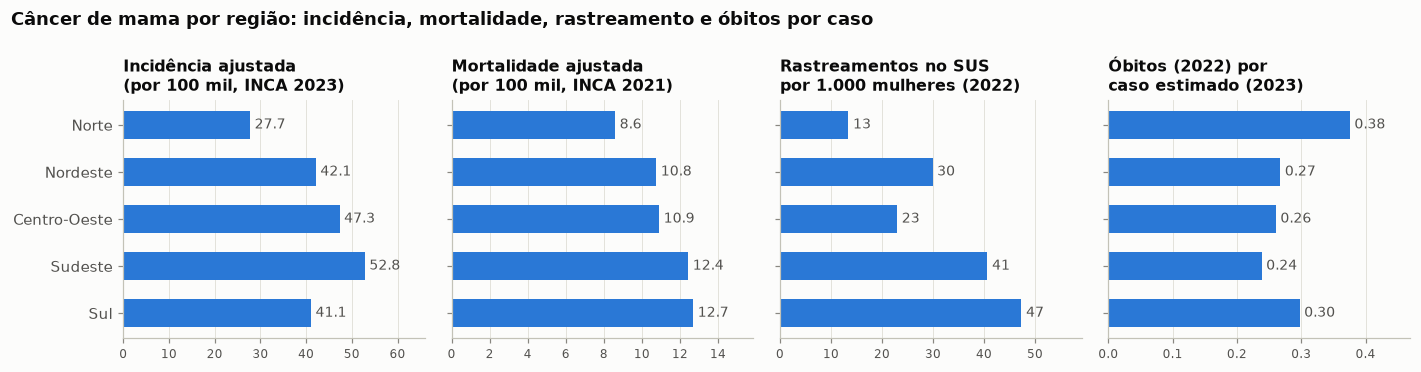

In [11]:
paineis = [
    ("taxa_incidencia_ajustada", "Incidência ajustada\n(por 100 mil, INCA 2023)", "%.1f"),
    ("taxa_mortalidade_ajustada_2021", "Mortalidade ajustada\n(por 100 mil, INCA 2021)", "%.1f"),
    ("rastreamentos_por_1000_mulheres", "Rastreamentos no SUS\npor 1.000 mulheres (2022)", "%.0f"),
    ("obitos_por_caso_estimado", "Óbitos (2022) por\ncaso estimado (2023)", "%.2f"),
]
r = regioes.reindex(ORDEM_REGIOES[::-1])  # de cima para baixo: Norte → Sul
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
for ax, (col, titulo, fmt) in zip(axes, paineis):
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    barras = ax.barh(r.index, r[col], color=AZUL, height=0.6)
    ax.bar_label(barras, fmt=fmt, padding=3, color=estilo.TINTA_SECUNDARIA, fontsize=9)
    ax.set_xlim(0, r[col].max() * 1.25)
    ax.set_title(titulo, fontsize=10.5)
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Câncer de mama por região: incidência, mortalidade, rastreamento e óbitos por caso",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "20_regioes_indicadores")

### 1.4.2 Mapa por UF: rastreamento × incidência

Mapa em grade (cada quadrado é uma UF, na posição aproximada do mapa do Brasil). A grade dá o mesmo peso visual a
todas as UFs, o que num mapa geográfico não acontece (o Amazonas ocuparia o mapa todo e o DF quase sumiria).

,sigla,regiao,rastreamentos_por_1000,taxa_incidencia_ajustada
Roraima,RR,Norte,4.10,27.70
Distrito Federal,DF,Centro-Oeste,6.30,49.80
Tocantins,TO,Norte,8.50,35.70
Amazonas,AM,Norte,9.60,28.30
Pará,PA,Norte,13.40,23.90
Maranhão,MA,Nordeste,16.40,28.30
Rondônia,RO,Norte,21.30,37.00
Ceará,CE,Nordeste,21.30,54.10
Amapá,AP,Norte,22.20,20.00
Acre,AC,Norte,22.90,26.20


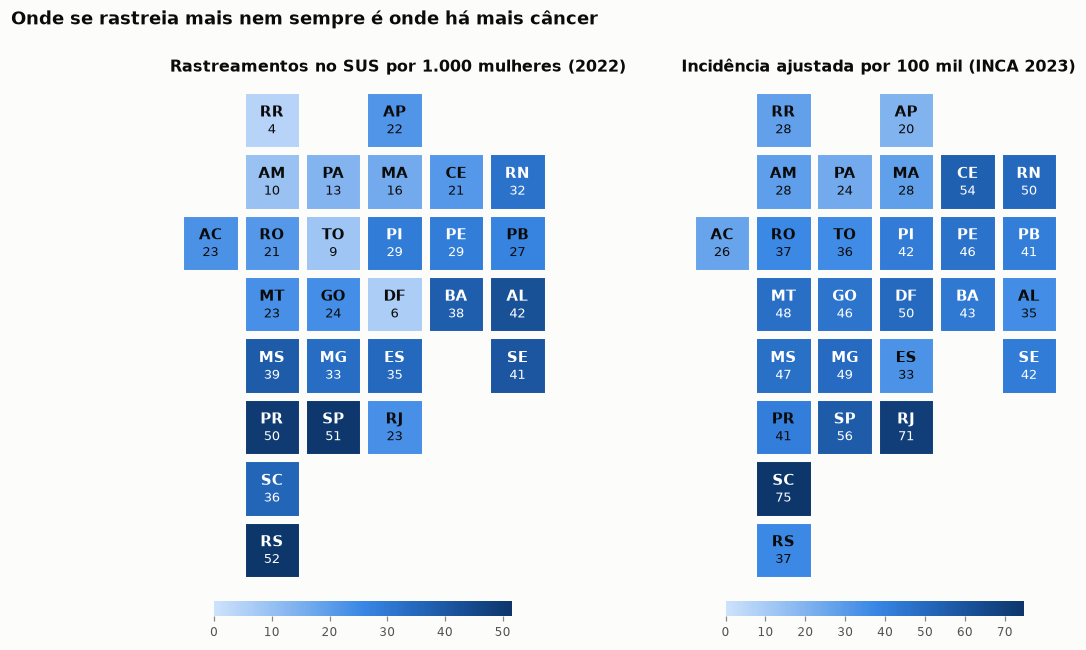

In [12]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle

GRADE_UF = {  # (linha, coluna)
    "RR": (0, 1), "AP": (0, 3),
    "AM": (1, 1), "PA": (1, 2), "MA": (1, 3), "CE": (1, 4), "RN": (1, 5),
    "AC": (2, 0), "RO": (2, 1), "TO": (2, 2), "PI": (2, 3), "PE": (2, 4), "PB": (2, 5),
    "MT": (3, 1), "GO": (3, 2), "DF": (3, 3), "BA": (3, 4), "AL": (3, 5),
    "MS": (4, 1), "MG": (4, 2), "ES": (4, 3), "SE": (4, 5),
    "PR": (5, 1), "SP": (5, 2), "RJ": (5, 3),
    "SC": (6, 1),
    "RS": (7, 1),
}
cmap = LinearSegmentedColormap.from_list("seq_azul", estilo.SEQUENCIAL_AZUL)
por_sigla = ufs.set_index("sigla")

fig, axes = plt.subplots(1, 2, figsize=(11, 6.4))
for ax, (col, titulo, fmt) in zip(axes, [
    ("rastreamentos_por_1000", "Rastreamentos no SUS por 1.000 mulheres (2022)", "{:.0f}"),
    ("taxa_incidencia_ajustada", "Incidência ajustada por 100 mil (INCA 2023)", "{:.0f}"),
]):
    norm = Normalize(vmin=0, vmax=por_sigla[col].max())
    for sigla, (lin, colu) in GRADE_UF.items():
        v = por_sigla.loc[sigla, col]
        ax.add_patch(Rectangle((colu, -lin), 0.92, 0.92, facecolor=cmap(norm(v)), edgecolor=estilo.FUNDO, lw=2))
        tinta = "white" if norm(v) > 0.55 else estilo.TINTA
        ax.text(colu + 0.46, -lin + 0.58, sigla, ha="center", va="center", fontsize=9.5, fontweight="bold", color=tinta)
        ax.text(colu + 0.46, -lin + 0.30, fmt.format(v), ha="center", va="center", fontsize=8.5, color=tinta)
    ax.set_xlim(-0.2, 6.1)
    ax.set_ylim(-7.2, 1.1)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(titulo, fontsize=10.5)
    barra = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, orientation="horizontal",
                         fraction=0.04, pad=0.02, shrink=0.7)
    barra.outline.set_visible(False)
    barra.ax.tick_params(labelsize=8, colors=estilo.TINTA_SUAVE, labelcolor=estilo.TINTA_SECUNDARIA)
fig.suptitle("Onde se rastreia mais nem sempre é onde há mais câncer", x=0.01, ha="left", fontweight="bold")
salvar(fig, "21_mapa_uf_rastreamento_incidencia")

ufs.sort_values("rastreamentos_por_1000")[
    ["sigla", "regiao", "rastreamentos_por_1000", "taxa_incidencia_ajustada"]].round(1)

### 1.4.3 A pandemia em cada região

Rastreamentos de cada região em relação a 2019 (2019 = 100).

Observação: o Centro-Oeste tem em 2018 só cerca de 74% do volume de 2019. Pode ser expansão real da oferta ou registro incompleto no SIA naquele ano; por isso as comparações usam 2019 como base.

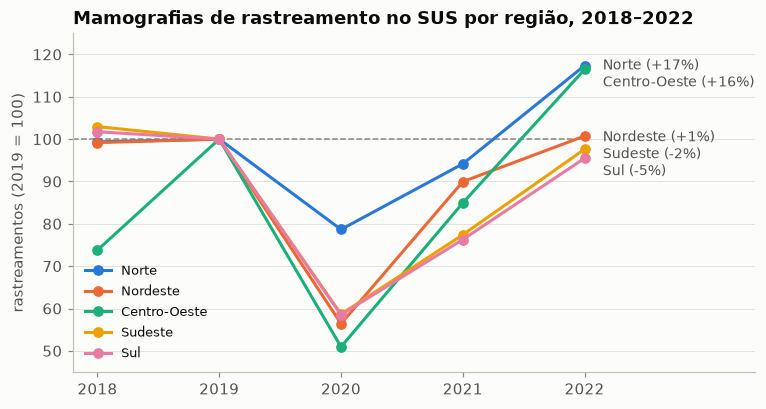

In [13]:
indice = 100 * rast_regiao_ano[ORDEM_REGIOES] / rast_regiao_ano.loc[2019, ORDEM_REGIOES]

fig, ax = plt.subplots(figsize=(8, 4))
for regiao, cor in zip(ORDEM_REGIOES, estilo.CORES):
    ax.plot(indice.index, indice[regiao], marker="o", markersize=6, color=cor, label=regiao)
# rótulos diretos no fim das linhas, afastados para não se sobreporem
fim = indice.loc[2022].sort_values()
posicoes = fim.values.copy()
for i in range(1, len(posicoes)):
    posicoes[i] = max(posicoes[i], posicoes[i - 1] + 4)
posicoes -= max(0, posicoes[-1] - fim.values[-1])  # empurra o bloco para baixo se o último subiu demais
for (regiao, v), y in zip(fim.items(), posicoes):
    ax.annotate(f"{regiao} ({v - 100:+.0f}%)", (2022, v), xytext=(2022.15, y), va="center",
                color=estilo.TINTA_SECUNDARIA, fontsize=9)
ax.hlines(100, 2017.8, 2022, color=estilo.TINTA_SUAVE, lw=1, ls="--", zorder=1)
ax.set_xticks(indice.index)
ax.set_xlim(2017.8, 2023.4)
ax.set_ylim(45, 125)
ax.set_ylabel("rastreamentos (2019 = 100)")
ax.legend(loc="lower left", fontsize=8.5, ncol=1)
ax.set_title("Mamografias de rastreamento no SUS por região, 2018–2022")
salvar(fig, "22_regioes_pandemia")

**Leitura (Brasil por região):**

- **Concentração no Sudeste:** a região tem cerca de 53% dos casos estimados com 42% das mulheres, e a maior
  incidência ajustada (52,8 por 100 mil). O Norte tem a menor (27,7), quase a metade.
- **O Norte é o caso mais preocupante:** menor cobertura de rastreamento (cerca de 13 exames por 1.000 mulheres,
  contra 47 no Sul), menor incidência registrada e, ainda assim, a **maior razão entre óbitos e casos** (0,38,
  contra 0,24 no Sudeste). O conjunto sugere **subdiagnóstico e diagnóstico mais tardio**. As UFs com menor
  cobertura são do Norte: Roraima, Tocantins, Amazonas e Pará.
- **O Sul rastreia mais e tem a maior mortalidade ajustada** (12,7). A mortalidade acompanha a incidência e a
  estrutura etária; o rastreamento não elimina essa diferença.
- **O Centro-Oeste rastreia pouco para a carga que tem:** é a região com menos exames por caso estimado (40).
- **Pandemia:** o Centro-Oeste e o Nordeste perderam mais exames em 2020. Em 2022, Norte e Centro-Oeste já estavam
  acima de 2019, enquanto Sudeste e Sul ainda estavam abaixo.
- No mapa, DF e RJ aparecem com cobertura muito baixa porque os dados são só do SUS, e nessas UFs uma parte grande
  das mulheres usa planos de saúde.

## 2. CBIS-DDSM

### 2.1 Unidade de análise

Cada linha dos CSVs é uma **lesão** (anormalidade), não uma paciente: uma mesma paciente pode ter várias lesões e
cada lesão aparece nas incidências CC e MLO. Os testes abaixo tratam lesões como independentes, o que é uma
simplificação (lesões da mesma paciente são correlacionadas).

In [14]:
cbis["breast_density"] = cbis["breast_density"].replace(0, np.nan)  # densidade 0 não existe no BI-RADS (2 registros)
resumo = pd.Series({
    "linhas (lesão × incidência)": len(cbis),
    "pacientes": cbis["patient_id"].nunique(),
    "massas": (cbis["abnormality_type"] == "mass").sum(),
    "calcificações": (cbis["abnormality_type"] == "calcification").sum(),
    "% malignas": 100 * cbis["maligno"].mean(),
    "densidade inválida (0)": cbis["breast_density"].isna().sum(),
})
resumo.to_frame("valor")

,valor
linhas (lesão × incidência),"3,568.00"
pacientes,"1,566.00"
massas,"1,696.00"
calcificações,"1,872.00"
% malignas,40.84
densidade inválida (0),2.00


### 2.2 Distribuição das características clínicas

- **Densidade mamária (BI-RADS 1–4):** 1 = predominantemente gordurosa ... 4 = extremamente densa;
- **BI-RADS (assessment):** 0 = inconclusivo, 1–2 = negativo/benigno, 3 = provavelmente benigno, 4 = suspeito, 5 = altamente suspeito;
- **Patologia:** maligna, benigna, ou benigna sem retorno (*benign without callback*).

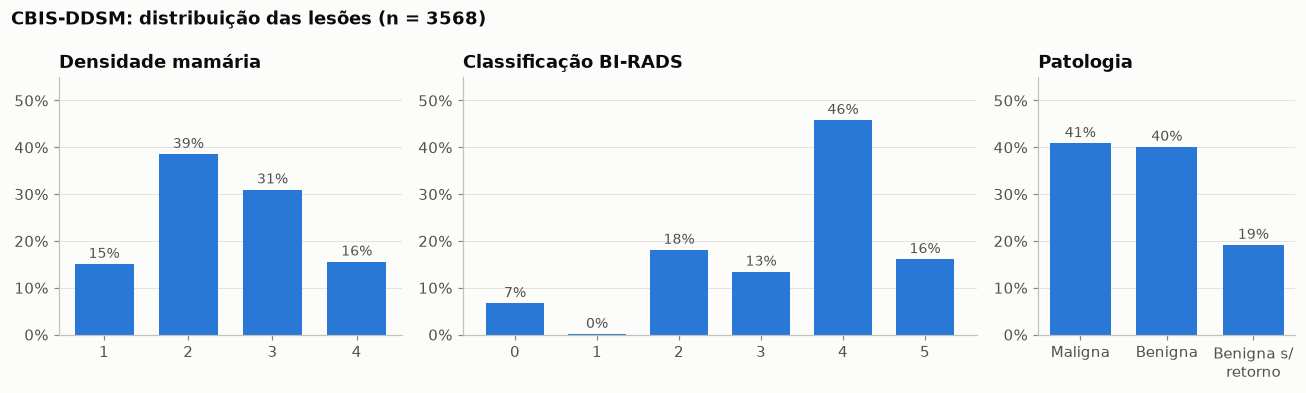

In [15]:
def distribuicao(col, ordem=None):
    s = cbis[col].value_counts(normalize=True).mul(100)
    return s.reindex(ordem) if ordem is not None else s

dens = distribuicao("breast_density", [1, 2, 3, 4])
birads = distribuicao("assessment", [0, 1, 2, 3, 4, 5])
pato = distribuicao("pathology", ["MALIGNANT", "BENIGN", "BENIGN_WITHOUT_CALLBACK"])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), gridspec_kw={"width_ratios": [4, 6, 3]})
for ax, s, titulo, rotulos in [
    (axes[0], dens, "Densidade mamária", ["1", "2", "3", "4"]),
    (axes[1], birads, "Classificação BI-RADS", ["0", "1", "2", "3", "4", "5"]),
    (axes[2], pato, "Patologia", ["Maligna", "Benigna", "Benigna s/\nretorno"]),
]:
    barras = ax.bar(rotulos, s.fillna(0).values, color=AZUL, width=0.7)
    ax.bar_label(barras, fmt="%.0f%%", padding=2, color=estilo.TINTA_SECUNDARIA, fontsize=9)
    ax.set_title(titulo)
    ax.set_ylim(0, 55)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
fig.suptitle("CBIS-DDSM: distribuição das lesões (n = %d)" % len(cbis), x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "05_cbis_distribuicoes")

### 2.3 Associação das características com malignidade

Proporção de lesões malignas em cada categoria, com teste qui-quadrado de independência e **V de Cramér**
(tamanho do efeito: ~0,1 fraco, ~0,3 moderado, ≥ 0,5 forte).

Categorias muito raras (BI-RADS 1, n = 3; sutileza 0, n = 2) são excluídas dos testes, porque deixam frequências
esperadas abaixo de 5 e invalidam a aproximação do qui-quadrado.

In [16]:
base_testes = cbis[(cbis["assessment"] != 1) & (cbis["subtlety"] != 0)]
testes = pd.DataFrame([teste_associacao(base_testes.dropna(subset=[v]), v)
                       for v in ["breast_density", "assessment", "abnormality_type", "subtlety"]])
testes["p_valor"] = testes["p_valor"].map(lambda p: f"{p:.1e}")
testes

,variavel,n,chi2,gl,p_valor,v_cramer,esperado_min
0,breast_density,3561,2.40,3,4.9e-01,0.00,218.10
1,assessment,3563,"1,315.40",4,1.5e-283,0.61,96.30
2,abnormality_type,3563,38.10,1,6.7e-10,0.10,690.10
3,subtlety,3563,50.60,4,2.7e-10,0.11,70.60


**Leitura:** a associação forte do BI-RADS com malignidade é esperada (e em parte circular): o BI-RADS é a
suspeita do radiologista, e a patologia é o resultado da biópsia indicada por essa suspeita. Já a **densidade
mamária praticamente não se associa à malignidade** nesta base (V ≈ 0). Isso não quer dizer que a densidade não
importa clinicamente; ela dificulta a *detecção*. Mas, entre lesões já detectadas e biopsiadas, a proporção de
malignas é a mesma em todas as densidades.

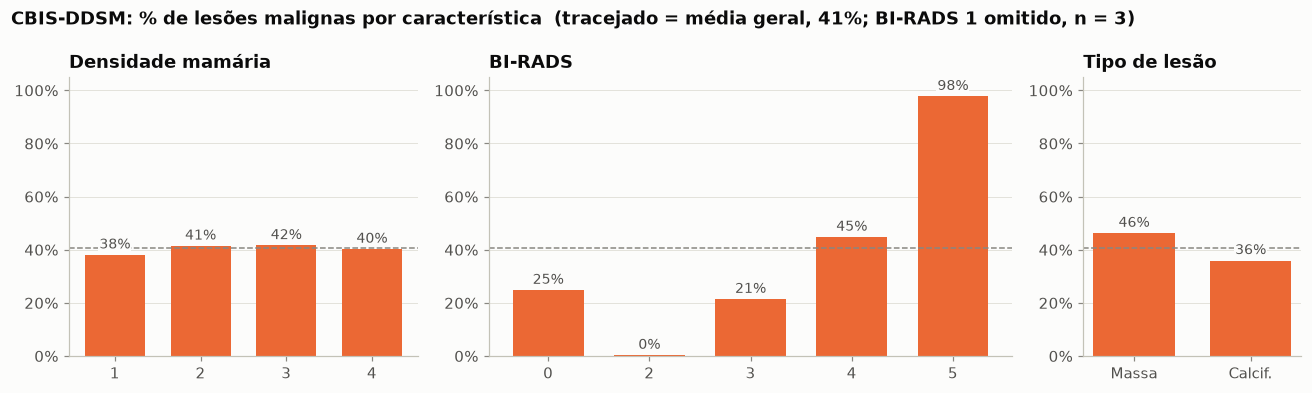

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), gridspec_kw={"width_ratios": [4, 6, 2.5]})
paineis = [
    (axes[0], "breast_density", [1, 2, 3, 4], "Densidade mamária"),
    (axes[1], "assessment", [0, 2, 3, 4, 5], "BI-RADS"),
    (axes[2], "abnormality_type", ["mass", "calcification"], "Tipo de lesão"),
]
for ax, var, ordem, titulo in paineis:
    taxa = cbis.groupby(var)["maligno"].mean().mul(100).reindex(ordem)
    rotulos = {"mass": "Massa", "calcification": "Calcif."}
    barras = ax.bar([rotulos.get(o, str(o)) for o in ordem], taxa.values, color=LARANJA, width=0.7)
    ax.axhline(100 * cbis["maligno"].mean(), color=estilo.TINTA_SUAVE, lw=1, ls="--", zorder=1)
    ax.bar_label(barras, fmt="%.0f%%", padding=2, color=estilo.TINTA_SECUNDARIA, fontsize=9,
                 bbox=dict(fc=estilo.FUNDO, ec="none", pad=0.6))  # o fundo esconde a linha atrás do número
    ax.set_title(titulo)
    ax.set_ylim(0, 105)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
fig.suptitle(f"CBIS-DDSM: % de lesões malignas por característica  (tracejado = média geral, "
             f"{100 * cbis['maligno'].mean():.0f}%; BI-RADS 1 omitido, n = 3)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "06_cbis_malignidade")

## 3. Brasil × CBIS-DDSM: o que dá para comparar

| Variável | CBIS-DDSM | Dados brasileiros coletados | Comparação |
|---|---|---|---|
| Idade | **ausente** (`PatientBirthDate` vazio nos 10.237 DICOMs) | SIM (óbitos), INCA (mamografias por faixa) | não é possível diretamente |
| Densidade mamária | sim | não coletada | não é possível (SISCAN seria a fonte) |
| BI-RADS | sim | não coletado | não é possível (SISCAN seria a fonte) |
| Proporção de malignidade | sim | indireta: casos novos ÷ mamografias | **ordem de grandeza** |
| Região / população | EUA, sem informação | UF e região | não é possível |

A comparação possível hoje é de **composição (case mix)**: quanto do conjunto é câncer.

In [18]:
mamografias_2022 = serie.loc[2022, "Total"]
casos_ano = inca_inc.query("indicador == 'casos_estimados' and nivel == 'brasil'")["valor"].iloc[0]
pct_brasil = 100 * casos_ano / mamografias_2022
pct_cbis = 100 * cbis["maligno"].mean()

comparacao = pd.Series({
    "CBIS-DDSM: % de lesões malignas": pct_cbis,
    "Brasil: casos novos/ano ÷ mamografias SUS 2022 (%)": pct_brasil,
    "Razão CBIS / Brasil": pct_cbis / pct_brasil,
})
comparacao.round(1).to_frame("valor")

,valor
CBIS-DDSM: % de lesões malignas,40.80
Brasil: casos novos/ano ÷ mamografias SUS 2022 (%),1.70
Razão CBIS / Brasil,23.60


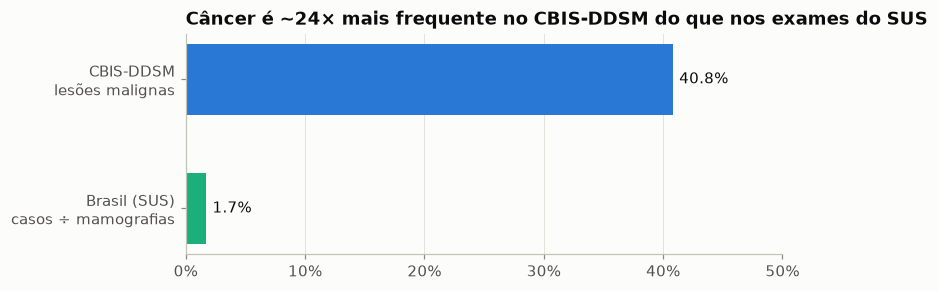

In [19]:
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
rotulos = ["Brasil (SUS)\ncasos ÷ mamografias", "CBIS-DDSM\nlesões malignas"]
barras = ax.barh(rotulos, [pct_brasil, pct_cbis], color=[VERDE_AGUA, AZUL], height=0.55)
ax.bar_label(barras, labels=[f"{pct_brasil:.1f}%", f"{pct_cbis:.1f}%"], padding=4, color=estilo.TINTA)
ax.set_xlim(0, 50)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_title(f"Câncer é ~{pct_cbis / pct_brasil:.0f}× mais frequente no CBIS-DDSM do que nos exames do SUS")
salvar(fig, "07_case_mix_brasil_cbis")

**Cuidados com esta razão:** ela é uma ordem de grandeza, não uma taxa de detecção. O numerador (casos novos
estimados para o país) inclui casos diagnosticados fora do SUS e sem mamografia, e o denominador conta exames, não
mulheres. Mesmo que a proporção real no SUS fosse o dobro ou o triplo, o CBIS-DDSM continuaria muitas vezes mais
"rico" em câncer. Isso é esperado: a base foi montada a partir de casos com lesão, para pesquisa em
detecção e classificação, e não como uma amostra de uma população rastreada.

## 4. Conclusões preliminares

1. **Composição (case mix):** 41% das lesões do CBIS-DDSM são malignas, contra cerca de 1,7 caso novo para cada
   100 mamografias feitas no SUS, uma diferença de ~24×. Modelos treinados no CBIS-DDSM aprendem com uma
   prevalência de câncer muito acima da encontrada no rastreamento brasileiro. Isso afeta diretamente métricas como
   o valor preditivo positivo e a taxa de falsos positivos quando o modelo é aplicado no SUS.
2. **Idade, a variável mais importante, não existe no CBIS-DDSM.** No Brasil, 22% dos óbitos por câncer de mama
   ocorrem antes dos 50 anos e 33% aos 70 ou mais, fora da faixa-alvo do rastreamento (50–69). Além disso, 27% das
   mamografias de rastreamento do SUS são feitas em mulheres de 40 a 49 anos. Não é possível verificar se a base
   cobre bem essas faixas.
3. **Densidade mamária:** no CBIS-DDSM ela não se associa à malignidade (V ≈ 0). A distribuição de densidade das
   brasileiras não foi coletada. Sem ela, a comparação mais relevante para viés de imagem fica em aberto.
4. **O Brasil não é homogêneo:** a incidência ajustada vai de 27,7 (Norte) a 52,8 (Sudeste) por 100 mil, e a
   intensidade do rastreamento por caso estimado varia de 40 (Centro-Oeste) a 66 (Sul). Perguntar se a base
   "representa o Brasil" envolve também perguntar *qual* Brasil. O Norte combina a menor cobertura de
   rastreamento (cerca de 13 exames por 1.000 mulheres, contra 47 no Sul) com a maior razão entre óbitos e casos,
   o que sugere diagnóstico mais tardio (seção 1.4).
5. **A pandemia derrubou 40% das mamografias em 2020**, com recuperação só em 2022. Isso deve ser considerado em
   qualquer análise temporal do período.
